# U02.LAB07 / U02.E04 · Visión computacional: CNN reproducible con Fashion-MNIST

**Asignatura:** INF-8239 Ciencia de Datos II
**Unidad:** 02 · Procesamiento de Lenguaje Natural, redes y visión
**Código:** U02.LAB07 (evidencia para U02.E04)

Compara un baseline denso contra una CNN pequeña sobre Fashion-MNIST, bajo una óptica de Green AI
(desempeño vs. parámetros, tiempo de entrenamiento e inferencia). Reutiliza
`src/inf8239_u02_cv/` — no duplica lógica de `scripts/train_cv.py`.

Requiere TensorFlow instalado (`uv sync --extra cpu`) y conexión a internet la primera vez (Fashion-MNIST
se descarga a la caché local de Keras).

In [1]:
import sys
from pathlib import Path

SRC = Path.cwd().parent / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

import json
import os
import random
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score

from inf8239_u02_cv.data import normalize_images, validate_images
from inf8239_u02_cv.models import build_cnn, build_dense

SEED = 42
os.environ.setdefault("TF_DETERMINISTIC_OPS", "1")
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU detectada:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0


GPU detectada: []


## Paso 1 · Cargar y validar el dataset

Fashion-MNIST: 60,000 imágenes de entrenamiento + 10,000 de prueba, escala de grises, 28×28.
Se separan 6,000 imágenes del set de entrenamiento como validación (mismo protocolo que
`scripts/train_cv.py`, para que notebook y script sean comparables). `normalize_images` y
`validate_images` son el mismo contrato que usan las pruebas automatizadas.

In [2]:
(x_train_all, y_train_all), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()
x_train_all = normalize_images(x_train_all)
x_test = normalize_images(x_test)

x_train, y_train = x_train_all[:-6000], y_train_all[:-6000]
x_valid, y_valid = x_train_all[-6000:], y_train_all[-6000:]

validate_images(x_train, y_train)
validate_images(x_valid, y_valid)
validate_images(x_test, y_test)

print("Entrenamiento:", x_train.shape, " Validación:", x_valid.shape, " Prueba:", x_test.shape)

Entrenamiento: (54000, 28, 28, 1)  Validación: (6000, 28, 28, 1)  Prueba: (10000, 28, 28, 1)


## Paso 2 · Análisis exploratorio

Distribución de clases (debe estar perfectamente balanceada por diseño del dataset) y una
muestra visual real de las imágenes con su etiqueta — evidencia visual legible, no una
descripción de código.

  Camiseta/top: 5370
      Pantalón: 5416
        Suéter: 5398
       Vestido: 5395
        Abrigo: 5367
      Sandalia: 5409
        Camisa: 5435
     Zapatilla: 5445
         Bolso: 5384
          Bota: 5381


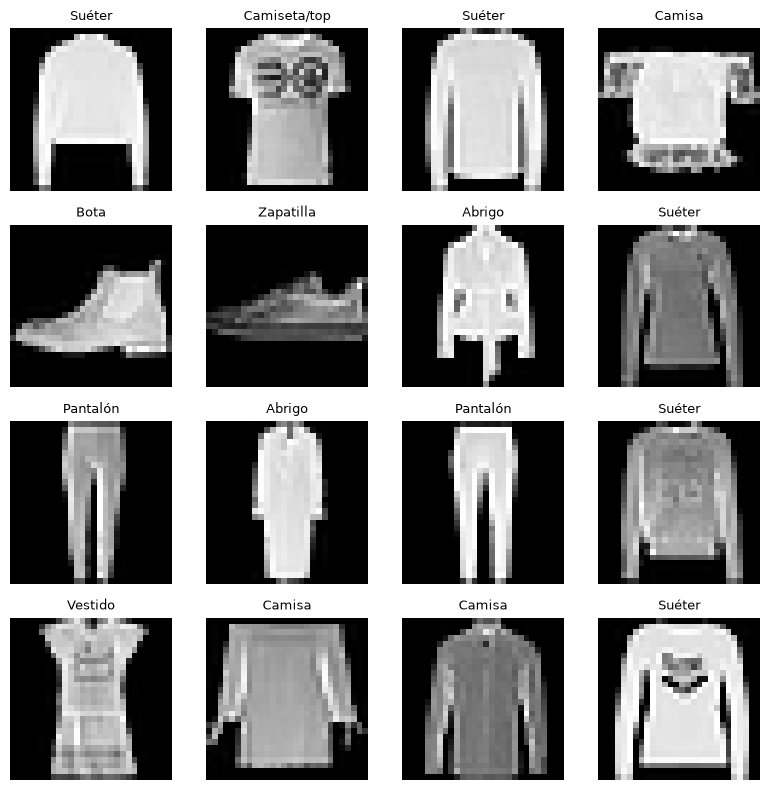

In [3]:
CLASS_NAMES = ["Camiseta/top", "Pantalón", "Suéter", "Vestido", "Abrigo",
               "Sandalia", "Camisa", "Zapatilla", "Bolso", "Bota"]

unique, counts = np.unique(y_train, return_counts=True)
for u, c in zip(unique, counts):
    print(f"{CLASS_NAMES[u]:>14}: {c}")

rng = np.random.default_rng(SEED)
sample_idx = rng.choice(len(x_train), size=16, replace=False)
fig, axes = plt.subplots(4, 4, figsize=(8, 8))
for axis, idx in zip(axes.ravel(), sample_idx):
    axis.imshow(x_train[idx].squeeze(), cmap="gray")
    axis.set_title(CLASS_NAMES[y_train[idx]], fontsize=9)
    axis.axis("off")
fig.tight_layout()
reports = Path.cwd().parent / "reports"
reports.mkdir(exist_ok=True)
fig.savefig(reports / "sample_images.png", dpi=170)
plt.show()

## Paso 3 · Entrenar baseline denso y CNN

Misma partición, mismo número de épocas, mismo optimizador para ambos modelos — comparación
justa. `EarlyStopping` conserva los mejores pesos de validación; el mejor punto de la CNN se
guarda en `models/best_cnn.keras`, igual que hace `scripts/train_cv.py`.

In [4]:
EPOCHS = 8

def compile_model(model):
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

models_dir = Path.cwd().parent / "models"
models_dir.mkdir(exist_ok=True)

metrics = {}
trained = {}
for name, factory in {"dense": build_dense, "cnn": build_cnn}.items():
    model = compile_model(factory(tf))
    callbacks = [tf.keras.callbacks.EarlyStopping(patience=2, restore_best_weights=True)]
    if name == "cnn":
        callbacks.append(tf.keras.callbacks.ModelCheckpoint(models_dir / "best_cnn.keras", save_best_only=True))
    start = perf_counter()
    model.fit(x_train, y_train, validation_data=(x_valid, y_valid), epochs=EPOCHS,
              batch_size=128, callbacks=callbacks, verbose=2)
    train_seconds = perf_counter() - start
    start = perf_counter()
    probabilities = model.predict(x_test, verbose=0)
    inference_seconds = perf_counter() - start
    predictions = probabilities.argmax(axis=1)
    metrics[name] = {
        "f1_macro": float(f1_score(y_test, predictions, average="macro")),
        "parameters": int(model.count_params()),
        "train_seconds": train_seconds,
        "inference_ms_per_image": 1000 * inference_seconds / len(x_test),
    }
    trained[name] = (model, predictions)

(reports / "cv_metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")
metrics

Epoch 1/8


422/422 - 2s - 5ms/step - accuracy: 0.7977 - loss: 0.6009 - val_accuracy: 0.8407 - val_loss: 0.4510


Epoch 2/8


422/422 - 1s - 2ms/step - accuracy: 0.8508 - loss: 0.4320 - val_accuracy: 0.8535 - val_loss: 0.4120


Epoch 3/8


...

Epoch 7/8


422/422 - 17s - 40ms/step - accuracy: 0.7459 - loss: 0.7204 - val_accuracy: 0.7945 - val_loss: 0.6118


Epoch 8/8


422/422 - 17s - 41ms/step - accuracy: 0.7546 - loss: 0.6961 - val_accuracy: 0.7987 - val_loss: 0.5879


{'dense': {'f1_macro': 0.8636756658952786,
  'parameters': 50890,
  'train_seconds': 9.510322399961296,
  'inference_ms_per_image': 0.06293743000132963},
 'cnn': {'f1_macro': 0.789009820711066,
  'parameters': 19466,
  'train_seconds': 142.1435923000099,
  'inference_ms_per_image': 0.15211359999957494}}

## Paso 4 · Comparación Green AI

No se concluye que el modelo con mayor F1 es automáticamente el mejor: se compara también
parámetros, tiempo de entrenamiento y tiempo de inferencia por imagen, para poder juzgar si la
mejora predictiva justifica el costo adicional.

In [5]:
import csv

rows = []
for name in ("dense", "cnn"):
    row = dict(metrics[name])
    row["modelo"] = name
    row["mejora_f1_vs_dense"] = metrics[name]["f1_macro"] - metrics["dense"]["f1_macro"]
    rows.append(row)

fieldnames = ["modelo", "f1_macro", "parameters", "train_seconds", "inference_ms_per_image", "mejora_f1_vs_dense"]
with open(reports / "green_ai_comparison.csv", "w", newline="", encoding="utf-8") as fh:
    writer = csv.DictWriter(fh, fieldnames=fieldnames)
    writer.writeheader()
    writer.writerows(rows)

for row in rows:
    print(row)


{'f1_macro': 0.8636756658952786, 'parameters': 50890, 'train_seconds': 9.510322399961296, 'inference_ms_per_image': 0.06293743000132963, 'modelo': 'dense', 'mejora_f1_vs_dense': 0.0}
{'f1_macro': 0.789009820711066, 'parameters': 19466, 'train_seconds': 142.1435923000099, 'inference_ms_per_image': 0.15211359999957494, 'modelo': 'cnn', 'mejora_f1_vs_dense': -0.0746658451842126}


## Paso 5 · Matriz de confusión y reporte por clase (CNN)

Evidencia visual real del modelo seleccionado, no una captura de código.

              precision    recall  f1-score   support

Camiseta/top      0.646     0.805     0.717      1000
    Pantalón      0.990     0.929     0.959      1000
      Suéter      0.702     0.649     0.675      1000
     Vestido      0.753     0.845     0.796      1000
      Abrigo      0.659     0.670     0.664      1000
    Sandalia      0.950     0.883     0.916      1000
      Camisa      0.501     0.364     0.422      1000
   Zapatilla      0.854     0.953     0.901      1000
       Bolso      0.916     0.937     0.926      1000
        Bota      0.934     0.896     0.915      1000

    accuracy                          0.793     10000
   macro avg      0.791     0.793     0.789     10000
weighted avg      0.791     0.793     0.789     10000



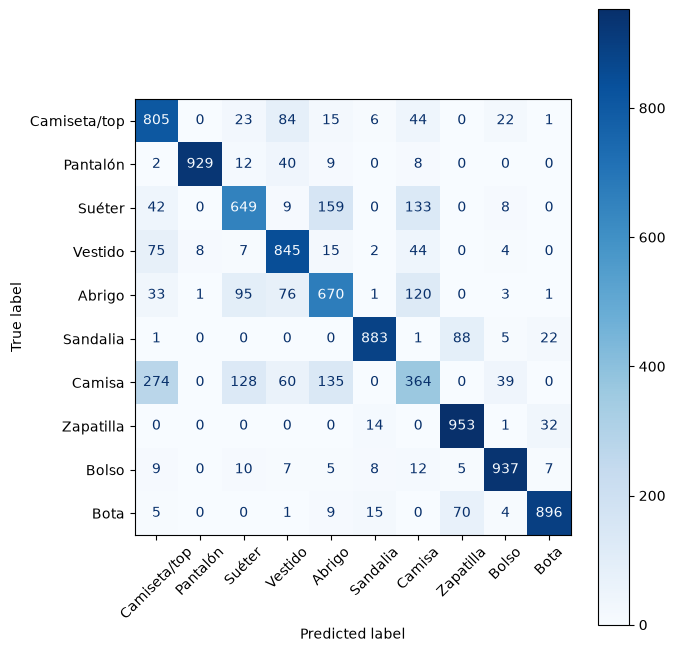

In [6]:
_, predictions = trained["cnn"]
print(classification_report(y_test, predictions, target_names=CLASS_NAMES, digits=3))

ConfusionMatrixDisplay.from_predictions(y_test, predictions, cmap="Blues",
                                         display_labels=CLASS_NAMES, xticks_rotation=45)
plt.gcf().set_size_inches(7, 7)
plt.tight_layout()
plt.savefig(reports / "confusion_cnn.png", dpi=170, bbox_inches="tight")
plt.show()

## Paso 6 · Errores visuales

Primeros 16 errores de clasificación: clase real (R) vs. predicha (P). Revise si hay pares
visualmente parecidos (p. ej. camisa/abrigo/suéter) o ejemplos genuinamente ambiguos.

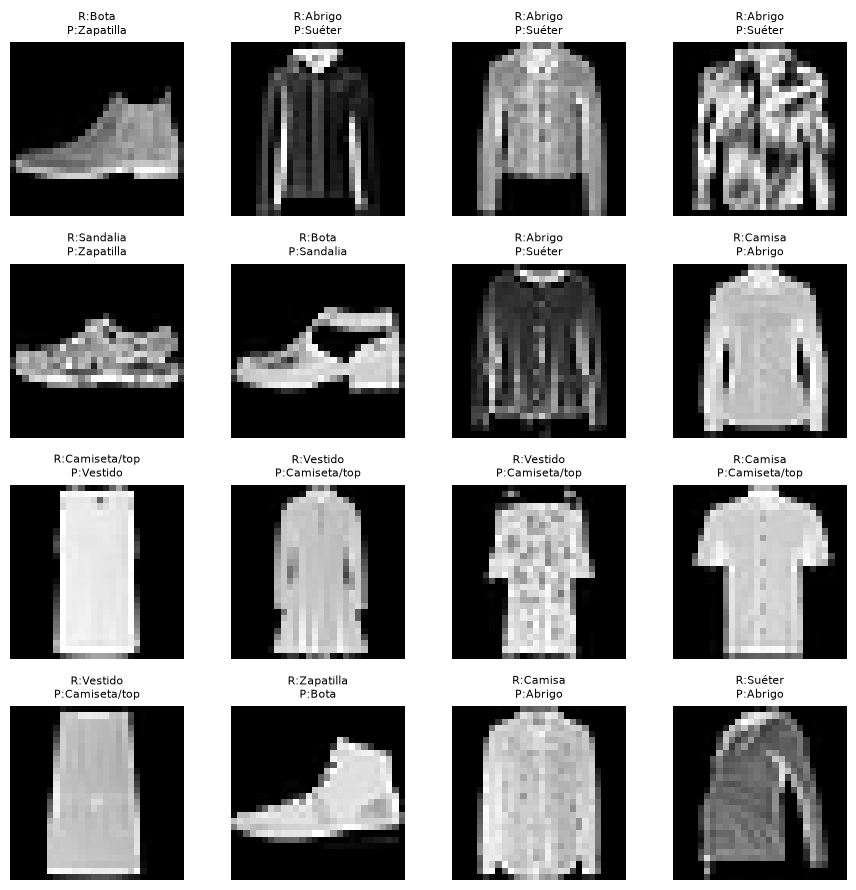

Errores totales: 2069 de 10000 (20.7%)


In [7]:
wrong = np.where(predictions != y_test)[0][:16]
fig, axes = plt.subplots(4, 4, figsize=(9, 9))
for axis, idx in zip(axes.ravel(), wrong):
    axis.imshow(x_test[idx].squeeze(), cmap="gray")
    axis.set_title(f"R:{CLASS_NAMES[y_test[idx]]}\nP:{CLASS_NAMES[predictions[idx]]}", fontsize=8)
    axis.axis("off")
fig.tight_layout()
fig.savefig(reports / "cnn_errors.png", dpi=170)
plt.show()

print(f"Errores totales: {(predictions != y_test).sum()} de {len(y_test)} "
      f"({(predictions != y_test).mean():.1%})")

## Paso 7 · Entorno de ejecución (reproducibilidad)

In [8]:
import platform
import sklearn
import datetime

print("Fecha de ejecución:", datetime.datetime.now().isoformat(timespec="seconds"))
print("Python:", sys.version.split()[0])
print("Plataforma:", platform.platform())
print("TensorFlow:", tf.__version__)
print("scikit-learn:", sklearn.__version__)
print("GPU usada:", bool(tf.config.list_physical_devices("GPU")))

Fecha de ejecución: 2026-10-20T20:41:34
Python: 3.12.15
Plataforma: Windows-11-10.0.26300-SP0
TensorFlow: 2.21.0
scikit-learn: 1.9.1
GPU usada: False


## Paso 8 · Cierre interpretativo (redacción del estudiante)

**Esta celda es texto, no código — requiere criterio humano, no se completa automáticamente.**

> *Nota de transparencia (ver `docs/USO_DE_IA.md`): el estudiante tuvo dificultad para redactar
> esta sección y pidió un borrador a la IA. El texto de abajo es una PROPUESTA basada
> estrictamente en los resultados reales de arriba (sin inventar ningún número) — léelo, ajústalo
> a tu propio criterio y asegúrate de poder explicar cada punto antes de entregar.*

- **Resultado principal:** Bajo la misma partición y 8 épocas de entrenamiento, el baseline denso
  (F1 macro 0.864) superó a la CNN pequeña (F1 macro 0.789) en este benchmark.
- **Evidencia predictiva:** El reporte por clase de la CNN (Paso 5) da accuracy global 0.793 y F1
  macro 0.789, con desempeño muy desigual entre clases: desde 0.959 (Pantalón) hasta 0.422
  (Camisa). La matriz de confusión (`reports/confusion_cnn.png`) muestra que los errores no son
  aleatorios, sino concentrados entre prendas superiores visualmente parecidas.
- **Clase más difícil:** Camisa (clase 6), con precisión 0.501, recall 0.364 y F1 0.422 — se
  confunde sobre todo con Camiseta/top, Suéter y Abrigo (ver `reports/cnn_errors.png`).
- **Costo comparado:** La CNN entrenó en ~142 s frente a ~9.5 s del baseline denso (~15× más
  lento) y, en esta corrida, también fue más lenta por imagen en inferencia (~0.152 ms vs. ~0.063
  ms), pese a tener menos parámetros (19,466 vs. 50,890).
- **¿La mejora justifica el costo?:** No. La CNN no solo no mejoró el F1 (quedó 0.075 puntos por
  debajo del baseline, según `mejora_f1_vs_dense` en `reports/green_ai_comparison.csv`), también
  costó más en entrenamiento e inferencia. En este experimento el modelo más simple fue la mejor
  opción en ambos ejes.
- **Limitación del benchmark:** Fashion-MNIST son imágenes de 28×28 en escala de grises,
  centradas y recortadas, sin variación real de iluminación, fondo, ángulo u oclusión. Un
  resultado bueno o malo aquí no predice el desempeño en fotos reales de otro dominio.
- **Decisión antes de usar otro dominio:** Antes de aplicar cualquiera de los dos modelos a otro
  dominio (por ejemplo, fotos reales de ropa de un catálogo), habría que reentrenar y revalidar
  con datos de ese dominio — y, antes de descartar la CNN en general, probar con más épocas u
  otra arquitectura, ya que este resultado es específico de este presupuesto de cómputo y no una
  conclusión general sobre CNN vs. redes densas.

## Paso 9 · Siguientes pasos

1. Corra `uv run pytest -q` para confirmar que los contratos automatizados siguen en verde.
2. Complete `MODEL_CARD.md` con las métricas reales de `reports/cv_metrics.json` y
   `reports/green_ai_comparison.csv`.
3. Complete el cierre interpretativo del Paso 8 a mano.
4. Con esto, arme el PDF de entrega del Ejercicio 04.